# Maurer rose

The rose curve r = sin(6θ) has 12 petals. A Maurer rose doesn't follow the curve. It jumps 71°
at a time around it and draws straight chords between 361 points, which weave a web over the
petals. The rose itself goes on top in gold.

In [1]:
import math

from common import hsv
from nbturtle import render

## Points on the rose

`point(deg)` turns an angle into a point on the rose, in polar coordinates: at angle θ, the
distance from the center is `scale * sin(petals * θ)`.

In [2]:
PETALS = 6
STEP = 71
SCALE = 380


def point(deg, petals=PETALS, scale=SCALE):
    k = math.radians(deg)
    r = scale * math.sin(petals * k)
    return r * math.cos(k), r * math.sin(k)

## Chords, then the outline

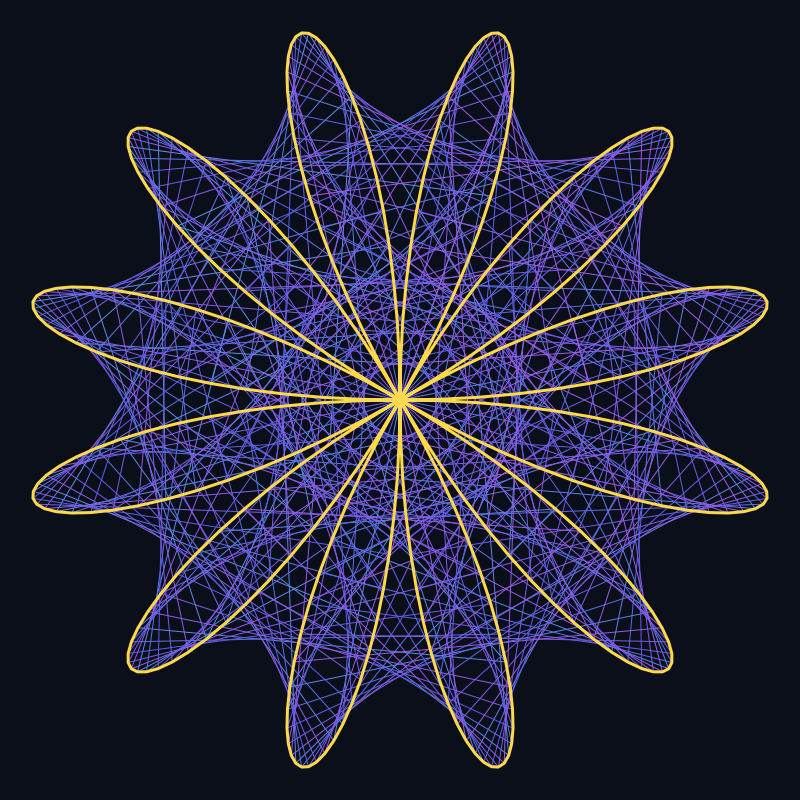

In [3]:
def draw(t):
    # thin chords, drifting from blue to violet
    t.pensize(1)
    t.goto(point(0))
    t.pendown()
    for i in range(1, 362):
        t.pencolor(hsv(0.6 + 0.15 * i / 361, 0.6, 0.9))
        t.goto(point(i * STEP))
    t.penup()
    # the rose itself as a golden outline
    t.pensize(3)
    t.pencolor((1.0, 0.85, 0.3))
    t.goto(point(0))
    t.pendown()
    for deg in range(1, 361):
        t.goto(point(deg))
    t.penup()


render(draw)

## The step decides everything

The same rose with steps of 1°, 29°, 59° and 97°. At 1° the chords are so short that they trace
the rose itself.

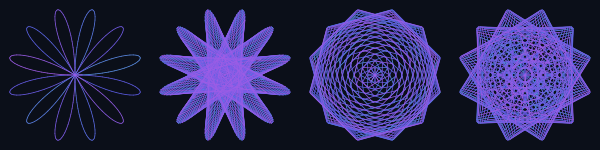

In [4]:
def web(t, step, cx, scale=90):
    t.pensize(1)
    for i in range(362):
        x, y = point(i * step, PETALS, scale)
        t.pencolor(hsv(0.6 + 0.15 * i / 361, 0.6, 0.9))
        t.goto(cx + x, y)
        t.pendown()
    t.penup()


def steps(t):
    for k, step in enumerate((1, 29, 59, 97)):
        web(t, step, -300 + k * 200)


render(steps, 800, 200, dpi=54)

## Try

- `PETALS = 5` with `STEP = 97`: an odd number gives 5 petals, not 10.
- Steps that divide 360, like 72 or 90, visit only a few points and draw a simple star.